In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_DIR = ROOT / "data" / "processed" / "lake_area_timeseries"
FIG_DIR = ROOT / "outputs" / "figures" / "presentation"

FIG_DIR.mkdir(parents=True, exist_ok=True)

print("CSV files:", len(list(DATA_DIR.glob("*.csv"))))

CSV files: 190


In [19]:
lakes = {
    "South Lhonak": "SPECIAL_SOUTH_LHONAK",
    "Thame": "SPECIAL_THAME",
    "Imja Tsho": "I2015_GL086925E27898N",
    "Tsho Rolpa": "I2015_GL086476E27861N"
}


lake_data = {}

for name, lake_id in lakes.items():
    df = pd.read_csv(DATA_DIR / f"{lake_id}.csv")

    df["date"] = pd.to_datetime(df["date"])
    df["year"] = df["date"].dt.year

    df["area_km2"] = pd.to_numeric(
        df["area_km2"], errors="coerce"
    )

    lake_data[name] = df

    print(name, ":", df["area_km2"].notna().sum(), "valid observations")

South Lhonak : 27 valid observations
Thame : 32 valid observations
Imja Tsho : 29 valid observations
Tsho Rolpa : 33 valid observations


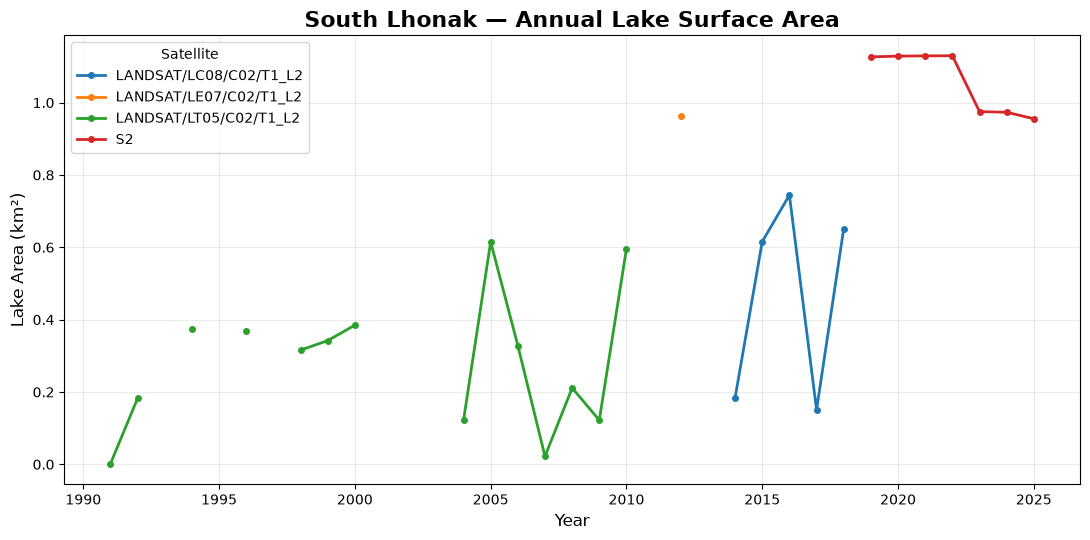

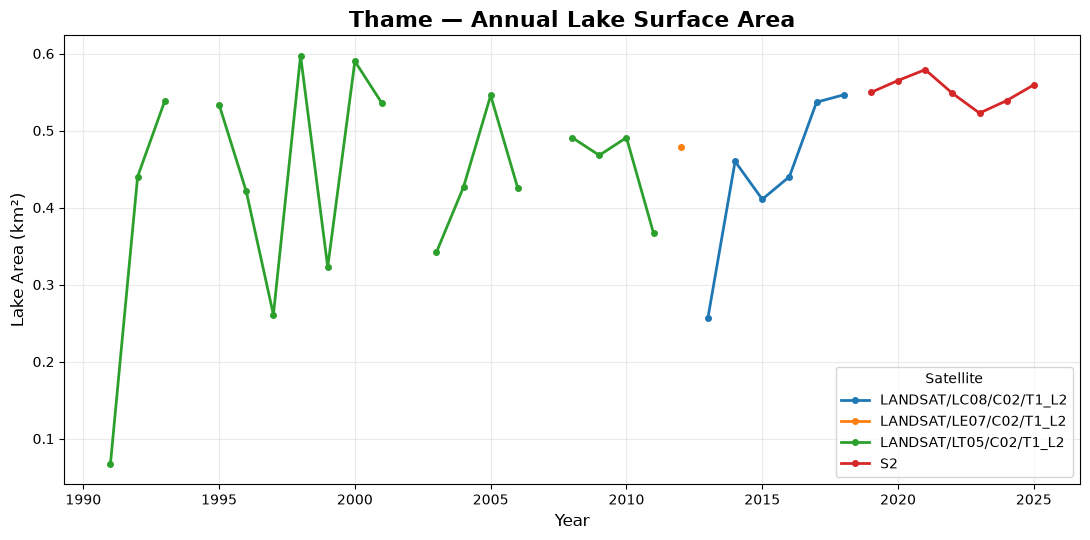

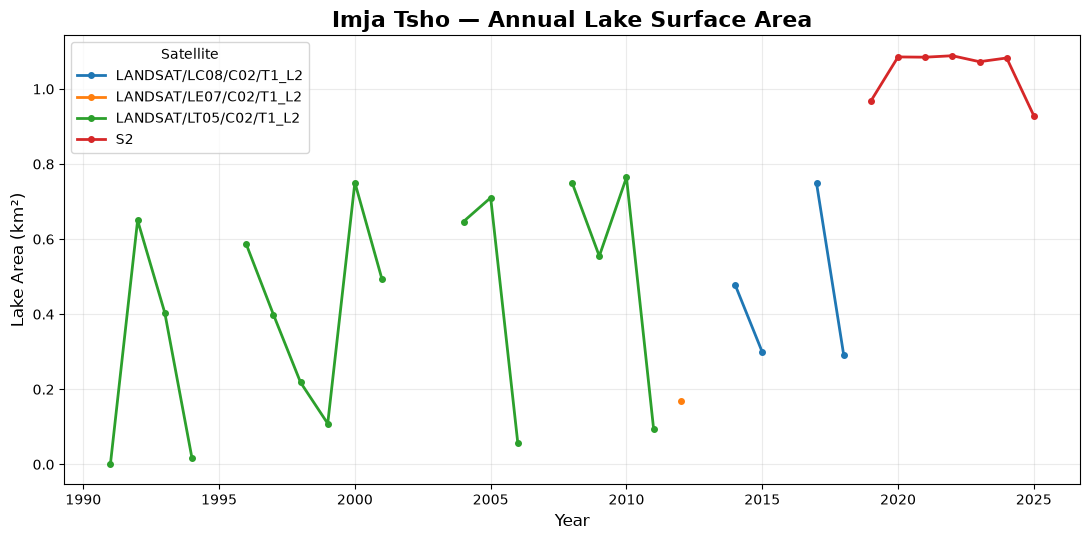

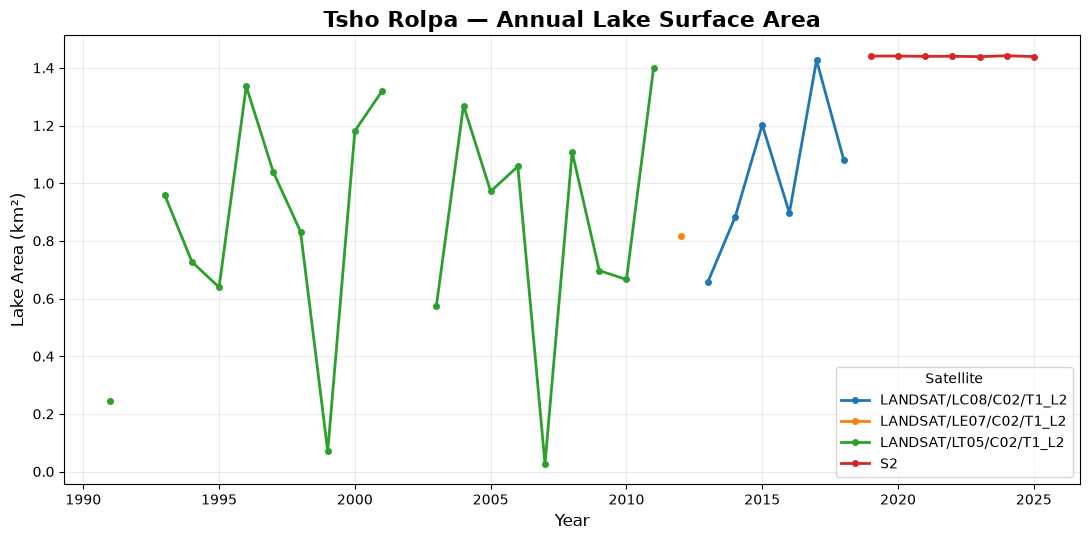

In [20]:
for name, df in lake_data.items():

    fig, ax = plt.subplots(figsize=(11, 5.5))

    for sensor, group in df.groupby("source"):
        group = group.sort_values("year")

        ax.plot(
            group["year"],
            group["area_km2"],
            marker="o",
            markersize=4,
            linewidth=2,
            label=sensor
        )

    ax.set_title(
        f"{name} — Annual Lake Surface Area",
        fontsize=16,
        fontweight="bold"
    )

    ax.set_xlabel("Year", fontsize=12)
    ax.set_ylabel("Lake Area (km²)", fontsize=12)

    ax.grid(alpha=0.25)
    ax.legend(title="Satellite")

    fig.tight_layout()

    fig.savefig(
        FIG_DIR / f"{name.lower().replace(' ', '_')}_area.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()